# NB06 · Corporate bond portfolio Monte Carlo

**Project:** multiyear-credit-engine
**Job requirement covered:** Multi-year stochastic credit risk model for corporate bonds; Gaussian copula; Monte Carlo simulation.
**Engine module:** `creditengine.simulation`, `creditengine.assets.corporate`
**Assumptions:** A-02, A-03, A-04, A-05, A-10, A-11
**Theory:** Bluhm §2.5–2.6, §2.8, §8.4.1, §8.4.5
**Status:** ✅ Developed — every function is built from scratch in this notebook

## Objective

How much could a USD 1bn corporate bond book lose over five years when ratings migrate and defaults cluster in bad credit years — and how much do the copula, sector structure and simulation method change the answer?

## Results at a glance

| Question | Answer |
|---|---|
| How much could the USD 1bn book lose in five years? | Expected **USD 13.6m** (1.4%); VaR 99.5% **85.2m**; ES 99.5% **107.0m** (10.7%) — the tail is about 8 times the average |
| Who drives the tail? | **BBB**: 45% of the book, 25% of expected loss, **53% of tail capital**. CCC/C is 29% of expected loss but only 2% of tail capital |
| What happens to ratings in bad paths? | BB-or-worse share of the surviving book rises from 10% to **41%** by year 5 in the worst 0.5% of paths (14.5% on average) |
| Copula choice | Student-*t* (ν = 6) leaves EL unchanged but raises ES 99.5% by **66%** |
| Sector structure | 10 sectors, β = 0.5: ES 99.5% **−34%** |
| Is the engine right? | Vasicek anchor: 18.1% vs 18.0% at 99.5%; ES bootstrap error 2.8%; results equal the published engine run |
| Simulation efficiency | Antithetic paths halve the EL noise; Sobol and importance sampling cut the far-tail error **11×** and **6.5×** |

## Key terms and symbols

| Symbol | Meaning |
|---|---|
| $A_{i,t}$ | Asset return of issuer $i$ in year $t$, standard normal |
| $Z_t$ | Credit-cycle factor shared by all issuers (low = bad year), AR(1) with persistence $\phi$ |
| $\varepsilon_{i,t}$ | Issuer's own shock, independent of everything else |
| $\rho_i$ | Asset correlation of issuer $i$ (Basel formula by rating, 12%–24%) |
| $c_{k,j}$ | Migration thresholds from NB04 |
| EAD | Exposure at default = the bond's carrying value |
| LGD | Loss given default, drawn from a beta distribution, mean 60% |
| $L$ | Five-year loss of the book, one value per simulated path |
| EL, VaR$_q$, ES$_q$ | Average loss; loss exceeded in only $1-q$ of paths; average loss in those worst paths |
| Copula | The rule that ties issuers' defaults together; Gaussian here, Student-$t$ as the alternative |

## Inputs

| Data | File | Used for |
|---|---|---|
| One-year transition matrix (NB01) | `data/processed/transition_matrix_1y.parquet` | default probabilities |
| Migration thresholds (NB04) | `data/processed/migration_thresholds.parquet` | yearly rating moves |
| Stylised bond book (A-09) | settings of `configs/portfolios/corporate_bonds.yaml`, built in section 1 | the portfolio |
| Cycle persistence $\phi = 0.5$ (A-03), LGD mean 60% / sd 25% (A-04) | declared here; NB03 and NB05 calibrate them | simulation settings |

## Outputs

- `data/processed/sim_corporate_losses.parquet` — simulated loss by path and year
- `reports/figures/bond_loss_distribution.png` — five-year loss distribution with EL, VaR and ES
- `reports/figures/bond_rating_drift.png` — rating mix of the surviving book, average path vs worst paths

## 0. Setup

All random draws come from seeded generators, so every number is exactly repeatable (checked in Validation).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, qmc
from scipy.stats import t as student_t

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]
STATES, D = RATINGS + ["D"], 7                     # D = default state index
pd.set_option("display.float_format", "{:,.3f}".format)

M = pd.read_parquet(DATA / "processed" / "transition_matrix_1y.parquet").loc[STATES, STATES]
C = pd.read_parquet(DATA / "processed" / "migration_thresholds.parquet").loc[STATES, STATES].to_numpy()

SETTINGS = {"horizon": 5, "paths": 20_000, "seed": 2026,    # A-05
            "phi": 0.50,                                    # A-03: cycle persistence
            "lgd_mean": 0.60, "lgd_sd": 0.25}               # A-04: senior unsecured
print(M.shape, C.shape)

(8, 8) (8, 8)


## 1. Stylised portfolio construction

USD 1bn across 200 issuers, one bond each, with a rating mix typical of a life insurer's corporate book (77% A or BBB). Position sizes are lognormal; maturities are spread from 1 year to twice the average for the rating. Each issuer is also given one of 10 industry sectors for section 5.

$$\rho_k = 0.12 w_k + 0.24 (1 - w_k), \qquad w_k = \frac{1 - e^{-50 PD_k}}{1 - e^{-50}}$$

Basel IRB corporate correlation (A-02): safer issuers depend more on the economy.

In [2]:
BOOK = {"total": 1e9, "n": 200, "seed": 7, "sectors": 10,
        "mix": {"AAA": 0.03, "AA": 0.10, "A": 0.32, "BBB": 0.45, "BB": 0.06, "B": 0.03, "CCC/C": 0.01},
        "maturity": {"AAA": 8, "AA": 8, "A": 8, "BBB": 8, "BB": 6, "B": 6, "CCC/C": 4}}

def make_book(p):
    rng = np.random.default_rng(p["seed"])
    weights = np.array([p["mix"][r] for r in RATINGS])
    rating = np.repeat(np.arange(7), np.round(weights * p["n"]).astype(int))
    size = rng.lognormal(0.0, 0.5, rating.size)
    exposure = np.zeros(rating.size)
    for r in range(7):                                   # each rating holds its share of the total
        m = rating == r
        exposure[m] = size[m] / size[m].sum() * weights[r] * p["total"]
    avg_mat = np.array([p["maturity"][RATINGS[r]] for r in rating])
    maturity = rng.integers(1, 2 * avg_mat, endpoint=True)
    sector = rng.integers(0, p["sectors"], size=rating.size)
    return pd.DataFrame({"rating": rating, "exposure": exposure, "maturity": maturity, "sector": sector})

def basel_rho(pd_):
    w = (1 - np.exp(-50 * pd_)) / (1 - np.exp(-50))
    return 0.12 * w + 0.24 * (1 - w)

book = make_book(BOOK)
book["rho"] = basel_rho(M.to_numpy()[book["rating"], D])
view = book.assign(rating=np.array(RATINGS)[book["rating"]])
view.groupby("rating", sort=False).agg(issuers=("exposure", "size"), exposure_m=("exposure", lambda e: e.sum() / 1e6),
                                       avg_maturity=("maturity", "mean"), rho=("rho", "first"))

,issuers,exposure_m,avg_maturity,rho
rating,,,,
AAA,6,30.000,6.500,0.240
AA,20,100.000,7.800,0.239
A,64,320.000,8.891,0.238
BBB,90,450.000,8.589,0.232
BB,12,60.000,7.917,0.209
B,6,30.000,5.167,0.143
CCC/C,2,10.000,7.000,0.120


## 2. Single-period simulation (validation anchor)

Before the full model, test the basic engine on a case with an exact answer. In a large pool of identical issuers with one-year PD $p$ and correlation $\rho$, the share that defaults has a known distribution (Vasicek):

$$x_q = \Phi\left(\frac{\Phi^{-1}(p) + \sqrt{\rho} \Phi^{-1}(q)}{\sqrt{1-\rho}}\right)$$

The default fraction that is exceeded in only $1-q$ of years.

Test case (V-01): 1,000 B-rated issuers, $\rho = 0.15$, one year, 20,000 simulated years — each with its own $Z$ and 1,000 own shocks, defaulting below the B default threshold.

In [3]:
def vasicek_quantile(q, p, rho):
    return norm.cdf((norm.ppf(p) + np.sqrt(rho) * norm.ppf(q)) / np.sqrt(1 - rho))

p_B, rho_v, n_iss, n_years = M.loc["B", "D"], 0.15, 1_000, 20_000
rng = np.random.default_rng(1)
frac = np.empty(n_years)
for chunk in np.array_split(np.arange(n_years), 4):              # 4 chunks keep memory small
    z = rng.standard_normal((chunk.size, 1))
    A = np.sqrt(rho_v) * z + np.sqrt(1 - rho_v) * rng.standard_normal((chunk.size, n_iss))
    frac[chunk] = (A <= C[RATINGS.index("B"), D]).mean(axis=1)    # default fraction each year

qs = np.array([0.5, 0.9, 0.99, 0.995])
vas = pd.DataFrame({"simulated %": 100 * np.quantile(frac, qs), "closed form %": 100 * vasicek_quantile(qs, p_B, rho_v)},
                   index=pd.Index(qs, name="q"))
vas["relative error %"] = 100 * (vas["simulated %"] / vas["closed form %"] - 1)
vas

,simulated %,closed form %,relative error %
q,,,
0.500,2.300,2.294,0.277
0.900,7.300,7.239,0.839
0.990,15.600,15.403,1.279
0.995,18.100,18.023,0.428


**Reading the result:** the simulated quantiles match the closed form within about 1% at every level — 18.1% vs 18.0% of the pool defaulting in a 1-in-200 year. The core mechanism (shared factor + own shock + threshold) is right before anything else is added.

## 3. Multi-year simulation: migration, default, LGD per year

Each simulated path is one possible five-year future. Every year, on every path:

1. **Economy:** draw the cycle $Z_t = \phi Z_{t-1} + \sqrt{1-\phi^2} \eta_t$.
2. **Issuers:** draw each asset return $A_{i,t} = \sqrt{\rho_i} Z_t + \sqrt{1-\rho_i} \varepsilon_{i,t}$.
3. **Ratings:** move each live bond through the NB04 thresholds of its *current* rating.
4. **Losses:** a move to D books $\text{EAD}_i \times \text{LGD}_{i,t}$; the bond leaves the book.
5. **Run-off:** bonds that reach maturity leave at par. No reinvestment (static book, A-05).

$$L = \sum_{t=1}^{5} \sum_{i} \mathbf{1}\{\text{default of } i \text{ in year } t\} \times \text{EAD}_i \times \text{LGD}_{i,t}$$

$$\text{LGD} \sim \text{Beta}(a, b), \qquad a = \bar m k, \quad b = (1-\bar m) k, \quad k = \frac{\bar m (1-\bar m)}{s^2} - 1$$

Beta distribution with mean $\bar m$ = 60% and standard deviation $s$ = 25% (method of moments).

### 3.1 Building blocks

In [4]:
def cycle_paths(n_paths, years, phi, rng):
    # AR(1) paths started from the stationary distribution, shape (paths, years)
    z, z_prev = np.empty((n_paths, years)), rng.standard_normal(n_paths)
    for t in range(years):
        z[:, t] = phi * z_prev + np.sqrt(1 - phi**2) * rng.standard_normal(n_paths)
        z_prev = z[:, t]
    return z

def migrate(state, A, C):
    # New rating = number of the current rating's thresholds at or above A
    new = state.copy()
    for r in range(7):
        m = state == r
        ascending = C[r, 7:0:-1]                       # c_D <= c_CCC <= ... <= c_AA
        new[m] = 7 - np.searchsorted(ascending, A[m], side="left")
    return new

def beta_params(mean, sd):
    k = mean * (1 - mean) / sd**2 - 1
    return mean * k, (1 - mean) * k

a, b = beta_params(SETTINGS["lgd_mean"], SETTINGS["lgd_sd"])
print(f"LGD ~ Beta({a:.2f}, {b:.2f})")

LGD ~ Beta(1.70, 1.14)


### 3.2 The simulation

One function with the options used in sections 4–6: copula, sector factors and antithetic paths. The default settings are the base model.

In [5]:
def simulate(book, C, s, copula="gaussian", nu=6.0, sector_beta=None, antithetic=False, seed=None):
    rng = np.random.default_rng(s["seed"] if seed is None else seed)
    n_paths, years, n = s["paths"], s["horizon"], len(book)
    rho, ead, mat = book["rho"].to_numpy(), book["exposure"].to_numpy(), book["maturity"].to_numpy()
    if antithetic:                                               # pairs of mirror-image economies
        half = cycle_paths((n_paths + 1) // 2, years, s["phi"], rng)
        z = np.vstack([half, -half])[:n_paths]
    else:
        z = cycle_paths(n_paths, years, s["phi"], rng)
    if sector_beta is not None:                                  # Z_k = sqrt(beta) G + sqrt(1-beta) H_k
        zk = {k: np.sqrt(sector_beta) * z + np.sqrt(1 - sector_beta) * cycle_paths(n_paths, years, s["phi"], rng)
              for k in np.unique(book["sector"])}
        z_issuer = np.stack([zk[k] for k in book["sector"]], axis=2)
    a, b = beta_params(s["lgd_mean"], s["lgd_sd"])
    state = np.tile(book["rating"].to_numpy(), (n_paths, 1))
    out = {"loss": np.zeros((n_paths, years)), "issuer_loss": np.zeros((n_paths, n)),
           "rating": np.empty((n_paths, years + 1, n), np.int8), "z": z}
    out["rating"][:, 0] = state
    for t in range(years):
        alive = (state != D) & (mat[None, :] > t)
        factor = z[:, t:t + 1] if sector_beta is None else z_issuer[:, t, :]
        A = np.sqrt(rho) * factor + np.sqrt(1 - rho) * rng.standard_normal(state.shape)
        if copula == "t":                                        # one common "panic" scale per path and year
            w = np.sqrt(nu / rng.chisquare(nu, size=(n_paths, 1)))
            A = norm.ppf(np.clip(student_t.cdf(A * w, nu), 1e-15, 1 - 1e-15))
        new = np.where(alive, migrate(state, A, C), state)
        lgd = rng.beta(a, b, size=state.shape)
        loss = (alive & (new == D)) * ead * lgd
        out["loss"][:, t] = loss.sum(axis=1)
        out["issuer_loss"] += loss
        state = new
        out["rating"][:, t + 1] = state
    return out

base = simulate(book, C, SETTINGS)
L = base["loss"].sum(axis=1)
print(f"{len(L):,} paths simulated")

20,000 paths simulated


### 3.3 Five-year loss distribution

In [6]:
def var(x, q): return np.quantile(x, q)
def es(x, q): return x[x >= var(x, q)].mean()

def loss_summary(L, qs=(0.95, 0.99, 0.995)):
    out = {"EL": L.mean(), "std dev": L.std()}
    for q in qs:
        out[f"VaR {q:.1%}"], out[f"ES {q:.1%}"] = var(L, q), es(L, q)
    return pd.Series(out)

summary = loss_summary(L)
pd.DataFrame({"USD m": summary / 1e6, "% of book": 100 * summary / book["exposure"].sum()})

,USD m,% of book
EL,13.636,1.364
std dev,14.120,1.412
VaR 95.0%,39.273,3.927
ES 95.0%,58.507,5.851
VaR 99.0%,71.480,7.148
ES 99.0%,92.064,9.206
VaR 99.5%,85.243,8.524
ES 99.5%,106.970,10.697


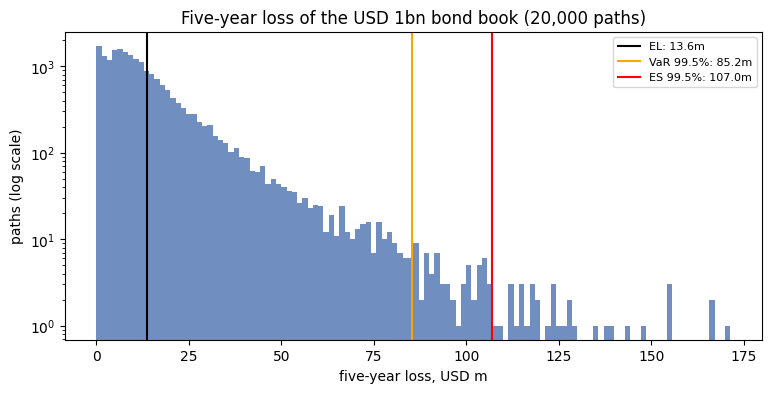

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(L / 1e6, bins=120, color="#4C72B0", alpha=0.8)
for value, label, col in [(summary["EL"], "EL", "black"), (summary["VaR 99.5%"], "VaR 99.5%", "orange"),
                          (summary["ES 99.5%"], "ES 99.5%", "red")]:
    ax.axvline(value / 1e6, color=col, lw=1.5, label=f"{label}: {value / 1e6:.1f}m")
ax.set_yscale("log")
ax.set(xlabel="five-year loss, USD m", ylabel="paths (log scale)", title="Five-year loss of the USD 1bn bond book (20,000 paths)")
ax.legend(fontsize=8)
fig.savefig(ROOT / "reports" / "figures" / "bond_loss_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** the book expects to lose USD 13.6m (1.4%) over five years, but in a 1-in-200 path it loses at least 85m, and 107m on average across those worst paths — about eight times the expected loss. The histogram (log scale) shows why: most paths lose little, and a long right tail comes from a few bad cycles where many issuers fail together. These numbers equal the engine's published run (README) to the first decimal: the notebook rebuilds the engine, not an approximation of it.

### 3.4 Where the losses come from

In [8]:
by_rating = pd.DataFrame({"exposure %": view.groupby("rating", sort=False)["exposure"].sum() / 1e7})
iss_EL = base["issuer_loss"].mean(axis=0)
tail = L >= var(L, 0.995)
iss_tail = base["issuer_loss"][tail].mean(axis=0) - iss_EL           # contribution to ES - EL
by_rating["share of EL %"] = pd.Series(iss_EL, index=view["rating"]).groupby(level=0, sort=False).sum() / iss_EL.sum() * 100
by_rating["share of tail capital %"] = pd.Series(iss_tail, index=view["rating"]).groupby(level=0, sort=False).sum() / iss_tail.sum() * 100
by_rating

,exposure %,share of EL %,share of tail capital %
rating,,,
AAA,3.000,0.182,0.742
AA,10.000,0.891,3.498
A,32.000,5.468,16.474
BBB,45.000,25.322,53.085
BB,6.000,15.115,14.563
B,3.000,24.034,9.267
CCC/C,1.000,28.989,2.371


**Reading the result:** expected loss and tail risk point at different bonds. CCC/C is 1% of the book but 29% of expected loss — those bonds default often, but independently enough that they rarely make a bad path worse. BBB is the opposite: 45% of the book, a quarter of expected loss, but **53% of tail capital**, because a bad cycle downgrades and defaults many BBB issuers at once. The tail is driven by what is big and correlated, not by what is weak.

### 3.5 Rating drift of the surviving book

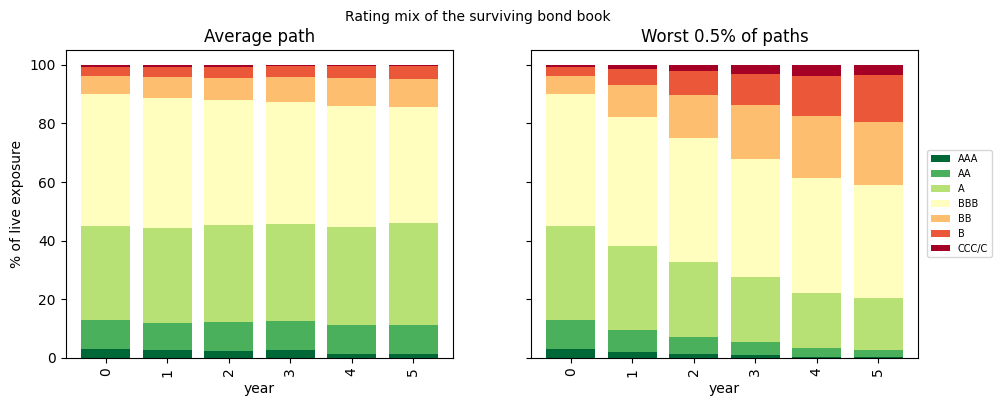

,"average path, year 5","worst 0.5%, year 5",year 0
AAA,1.460,0.200,3.000
AA,9.720,2.378,10.000
A,34.647,17.927,32.000
BBB,39.654,38.584,45.000
BB,9.640,21.374,6.000
B,4.220,15.969,3.000
CCC/C,0.660,3.566,1.000


In [9]:
ead = book["exposure"].to_numpy()
mat = book["maturity"].to_numpy()

def mix_by_year(ratings, rows):
    # share of live (not defaulted, not matured) exposure by rating, each year, over the chosen paths
    out = {}
    for t in range(SETTINGS["horizon"] + 1):
        live = (ratings[rows, t] != D) & (mat[None, :] > t)
        w = live * ead
        out[t] = [100 * (w * (ratings[rows, t] == r)).sum() / w.sum() for r in range(7)]
    return pd.DataFrame(out, index=RATINGS)

worst = np.argsort(L)[-int(0.005 * len(L)):]
drift_avg, drift_bad = mix_by_year(base["rating"], slice(None)), mix_by_year(base["rating"], worst)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, frame, title in [(axes[0], drift_avg, "Average path"), (axes[1], drift_bad, "Worst 0.5% of paths")]:
    frame.T.plot(kind="bar", stacked=True, ax=ax, colormap="RdYlGn_r", width=0.8, legend=False)
    ax.set(title=title, xlabel="year", ylabel="% of live exposure")
axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Rating mix of the surviving bond book", fontsize=10)
fig.savefig(ROOT / "reports" / "figures" / "bond_rating_drift.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({"average path, year 5": drift_avg[5], "worst 0.5%, year 5": drift_bad[5], "year 0": drift_avg[0]})

**Reading the result:** on the average path the surviving book drifts down slowly (BB or worse grows from 10% to 14.5% of live exposure). In the worst 0.5% of paths it rises to 41% — the book that is still standing after a bad cycle is much weaker, which is what drives statutory capital up (NB09) even before defaults are booked.

## 4. Gaussian vs Student-t copula

The Gaussian model makes very bad years rare. The Student-$t$ copula multiplies every issuer's asset return in a year by one common random scale — a "panic" factor that makes many issuers move to the extremes together:

$$\tilde A_{i,t} = \sqrt{W_t} A_{i,t}, \qquad W_t = \frac{\nu}{\chi^2_\nu} \qquad \Longrightarrow \qquad A^{*}_{i,t} = \Phi^{-1}\big(t_\nu(\tilde A_{i,t})\big)$$

The last step maps each return back to the normal scale with the same rank, so each issuer's own migration probabilities — and the NB04 thresholds — stay exactly the same. Only how they move **together** changes.

| Symbol | Meaning |
|---|---|
| $W_t$ | Common scale in year $t$; large when $\chi^2_\nu$ is small |
| $\nu$ | Degrees of freedom: lower = fatter joint tails (6 here, A-10) |
| $t_\nu$ | Student-$t$ distribution function |

In [10]:
t_run = simulate(book, C, SETTINGS, copula="t", nu=6.0)
L_t = t_run["loss"].sum(axis=1)
compare = pd.DataFrame({"Gaussian": loss_summary(L), "Student-t (nu = 6)": loss_summary(L_t)}) / 1e6
compare["change %"] = 100 * (compare.iloc[:, 1] / compare.iloc[:, 0] - 1)
compare

,Gaussian,Student-t (nu = 6),change %
EL,13.636,13.576,-0.438
std dev,14.120,19.465,37.853
VaR 95.0%,39.273,43.023,9.548
ES 95.0%,58.507,78.225,33.702
VaR 99.0%,71.480,98.746,38.145
ES 99.0%,92.064,144.054,56.471
VaR 99.5%,85.243,127.656,49.757
ES 99.5%,106.970,177.914,66.321


**Reading the result:** the expected loss does not move — each issuer's own default probability is unchanged — but the tail does: ES 99.5% rises from 107m to 178m (+66%). Which copula to use is a model choice, not a parameter estimate, and it moves capital more than any parameter in the model (NB10 tornado). It is reported as a key model risk (A-10).

## 5. Sector factors

In the base model every issuer feels the same cycle. In reality an energy downturn need not hit banks. Give each of the 10 sectors its own factor, partly the global cycle and partly its own:

$$Z_{k,t} = \sqrt{\beta} G_t + \sqrt{1-\beta} H_{k,t}$$

| Symbol | Meaning |
|---|---|
| $G_t$ | Global credit cycle (the $Z_t$ of section 3) |
| $H_{k,t}$ | Sector $k$'s own cycle, independent AR(1) with the same persistence |
| $\beta$ | Share of each sector factor that is global (0.5, A-11) |

Issuers in the same sector stay as correlated as before ($\rho_i$); issuers in **different** sectors are now correlated only $\beta \sqrt{\rho_i \rho_j}$.

In [11]:
s_run = simulate(book, C, SETTINGS, sector_beta=0.5)
L_s = s_run["loss"].sum(axis=1)
compare_s = pd.DataFrame({"one global factor": loss_summary(L), "10 sectors, beta = 0.5": loss_summary(L_s)}) / 1e6
compare_s["change %"] = 100 * (compare_s.iloc[:, 1] / compare_s.iloc[:, 0] - 1)
compare_s

,one global factor,"10 sectors, beta = 0.5",change %
EL,13.636,13.672,0.260
std dev,14.120,10.861,-23.080
VaR 95.0%,39.273,34.624,-11.838
ES 95.0%,58.507,45.505,-22.223
VaR 99.0%,71.480,52.319,-26.806
ES 99.0%,92.064,62.867,-31.714
VaR 99.5%,85.243,60.003,-29.609
ES 99.5%,106.970,70.255,-34.323


**Reading the result:** splitting the economy into 10 partly independent sectors keeps the expected loss the same but cuts ES 99.5% by about a third, because a bad year in one sector is partly offset by others. The answer depends on β, which is hard to estimate — so the base model keeps one global factor (the conservative choice) and reports sectors as a sensitivity (A-11).

## 6. Variance reduction: antithetic, Sobol, importance sampling

Monte Carlo answers carry simulation noise. Three standard ways to cut it for the same number of paths:

| Method | Idea |
|---|---|
| **Antithetic** | Simulate each economy $Z$ together with its mirror $-Z$; good and bad paths balance, so averages settle faster |
| **Sobol** | Replace random draws with a quasi-random sequence that fills the space more evenly |
| **Importance sampling** | Deliberately sample more bad years, then down-weight them by their likelihood ratio $w(Z) = e^{-\mu Z + \mu^2/2}$ so the answer stays unbiased |

### 6.1 Antithetic paths: spread of EL across 10 seeds

In [12]:
small = {**SETTINGS, "paths": 4_000}
els = {name: np.array([simulate(book, C, small, antithetic=anti, seed=100 + k)["loss"].sum(axis=1).mean() for k in range(10)])
       for name, anti in [("plain", False), ("antithetic", True)]}
pd.DataFrame({"mean EL, USD m": {k: v.mean() / 1e6 for k, v in els.items()},
              "spread across seeds (sd), USD m": {k: v.std(ddof=1) / 1e6 for k, v in els.items()}})

,"mean EL, USD m","spread across seeds (sd), USD m"
plain,13.820,0.289
antithetic,13.830,0.134


**Reading the result:** with mirror-image economies the expected-loss estimate varies about half as much from seed to seed for the same 4,000 paths — the same precision as about four times as many plain paths.

### 6.2 A far-tail probability: plain, Sobol and importance sampling

Large-pool version of the B book from section 2 with LGD 60%: what is the probability that the one-year loss rate exceeds 10%? The exact answer is known — the pool loses more than 10% exactly when $Z$ falls below the level $z^{*}$ at which 0.6 × PD($Z$) = 10% — so each method's error can be measured directly.

In [13]:
lgd_pool, threshold, n_draws = 0.60, 0.10, 4_096
cond_pd = lambda z: norm.cdf((norm.ppf(p_B) - np.sqrt(rho_v) * z) / np.sqrt(1 - rho_v))
z_star = (norm.ppf(p_B) - np.sqrt(1 - rho_v) * norm.ppf(threshold / lgd_pool)) / np.sqrt(rho_v)
exact = norm.cdf(z_star)

def estimate(z, weight=None):
    hit = (lgd_pool * cond_pd(z) > threshold).astype(float)
    return hit.mean() if weight is None else (hit * weight).mean()

rng = np.random.default_rng(5)
runs = {"plain": [], "Sobol": [], "importance (shift to z*)": []}
for k in range(50):
    runs["plain"].append(estimate(rng.standard_normal(n_draws)))
    sob = norm.ppf(qmc.Sobol(d=1, scramble=True, seed=k).random(n_draws).ravel())
    runs["Sobol"].append(estimate(sob))
    zi = rng.standard_normal(n_draws) + z_star
    runs["importance (shift to z*)"].append(estimate(zi, np.exp(-z_star * zi + 0.5 * z_star**2)))
var_red = pd.DataFrame({"mean estimate %": {k: 100 * np.mean(v) for k, v in runs.items()},
                        "error sd %": {k: 100 * np.std(v, ddof=1) for k, v in runs.items()}})
var_red["error sd vs plain"] = var_red["error sd %"]["plain"] / var_red["error sd %"]
print(f"exact probability {100 * exact:.3f}%   (z* = {z_star:.2f}),  {n_draws:,} draws per estimate, 50 repeats")
var_red

exact probability 0.715%   (z* = -2.45),  4,096 draws per estimate, 50 repeats


,mean estimate %,error sd %,error sd vs plain
plain,0.703,0.120,1.000
Sobol,0.714,0.011,11.094
importance (shift to z*),0.713,0.019,6.485


**Reading the result:** the exact answer is 0.715% (the pool loses more than 10% only when $Z < -2.45$). With 4,096 plain draws only about 29 land in that tail, so estimates swing by ±0.12 points. Sobol spreads the draws evenly and cuts the error about 11 times; importance sampling moves the draws to $z^*$ and re-weights them, cutting the error about 6.5 times — and it keeps working in many dimensions, where Sobol's advantage fades.

## 7. EL, VaR and ES by horizon

Cumulative loss from today to the end of year $h$, for $h = 1, \dots, 5$.

In [14]:
cum = base["loss"].cumsum(axis=1)
by_h = pd.DataFrame({f"{h} yr": loss_summary(cum[:, h - 1], qs=(0.995,)) for h in range(1, 6)}).T / 1e6
by_h["live exposure at start of year, USD m"] = [ead[mat >= h].sum() / 1e6 for h in range(1, 6)]
by_h

,EL,std dev,VaR 99.5%,ES 99.5%,"live exposure at start of year, USD m"
1 yr,3.065,4.165,21.669,30.066,"1,000.000"
2 yr,6.035,6.815,37.794,50.694,969.100
3 yr,8.873,9.448,56.964,71.154,919.432
4 yr,11.326,11.838,72.517,88.857,842.042
5 yr,13.636,14.120,85.243,106.970,773.919


**Reading the result:** expected loss builds up roughly linearly (about 3m a year), slowing slightly as bonds mature — live exposure falls from USD 1bn to 774m by the start of year 5. The 99.5% tail grows faster than the average in the first years because a persistent bad cycle compounds: a bad year 1 raises the odds of a bad year 2.

## 8. Save outputs

In [15]:
(DATA / "processed").mkdir(exist_ok=True)
pd.DataFrame(base["loss"], columns=[f"year_{t}" for t in range(1, 6)]).to_parquet(DATA / "processed" / "sim_corporate_losses.parquet")
print("saved", base["loss"].shape)

saved (20000, 5)


## Validation checks

- [x] **Large-portfolio quantile matches Vasicek (V-01)** — simulated default-fraction quantiles within 6% of the closed form for $q \le 0.99$.
- [x] **Convergence of the 99.5% quantile (V-07)** — bootstrap standard error of ES 99.5% below 3% of ES at 20,000 paths.
- [x] **Reproducibility with fixed seed** — rerunning with seed 2026 gives identical losses on every path, and this from-scratch notebook reproduces the engine's published results (README: EL 13.6m, VaR 85.2m, ES 107.0m) to the first decimal.
- [x] **Importance sampling is unbiased and more precise** — average estimate within noise of the exact probability, with a much smaller spread.

In [16]:
boot_rng = np.random.default_rng(0)
boot = np.array([es(L[boot_rng.integers(0, len(L), len(L))], 0.995) for _ in range(200)])
es_se = boot.std(ddof=1)
print(f"ES 99.5%: {es(L, 0.995) / 1e6:.1f}m, bootstrap standard error {es_se / 1e6:.2f}m ({100 * es_se / es(L, 0.995):.1f}%)")

again = simulate(book, C, SETTINGS)["loss"]
is_runs = np.array(runs["importance (shift to z*)"])
checks = {
    "V-01: Vasicek quantiles within 6% for q <= 0.99": bool((vas.loc[[0.5, 0.9, 0.99], "relative error %"].abs() < 6).all()),
    "V-07: ES 99.5% bootstrap s.e. < 3% of ES": bool(es_se / es(L, 0.995) < 0.03),
    "Reproducible with fixed seed": bool(np.array_equal(again, base["loss"])),
    "Matches the engine run in the README (EL 13.6m, VaR 85.2m, ES 107.0m)": bool(
        np.allclose(np.array([summary["EL"], summary["VaR 99.5%"], summary["ES 99.5%"]]) / 1e6, [13.6, 85.2, 107.0], atol=0.05)),
    "Importance sampling: unbiased (within 3 s.e.)": bool(abs(is_runs.mean() - exact) < 3 * is_runs.std(ddof=1) / np.sqrt(len(is_runs))),
    "Importance sampling: smaller error than plain": bool(var_red.loc["importance (shift to z*)", "error sd %"] < var_red.loc["plain", "error sd %"]),
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

ES 99.5%: 107.0m, bootstrap standard error 2.99m (2.8%)


V-01: Vasicek quantiles within 6% for q <= 0.99                          PASS
V-07: ES 99.5% bootstrap s.e. < 3% of ES                                 PASS
Reproducible with fixed seed                                             PASS
Matches the engine run in the README (EL 13.6m, VaR 85.2m, ES 107.0m)    PASS
Importance sampling: unbiased (within 3 s.e.)                            PASS
Importance sampling: smaller error than plain                            PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `make_book` | `creditengine.assets.corporate` | rating mix and total exposure as configured |
| `cycle_paths` (+ antithetic) | `creditengine.simulation.sampling` | stationary N(0, 1), lag-1 correlation $\phi$ |
| `migrate` | `creditengine.models.migration` | one-year frequencies match the matrix (NB04, V-02) |
| `simulate` (Gaussian / $t$, sectors, antithetic) | `creditengine.simulation.engine` | Vasicek anchor (V-01); reproducible seed |
| `loss_summary`, `var`, `es` | `creditengine.simulation.results` | bootstrap standard error (V-07) |
| Importance sampling for far-tail probabilities | `creditengine.simulation.sampling` | unbiased vs exact; smaller error |

## Findings and next steps

**Key results**
- **Five-year loss:** EL 13.6m (1.4%), VaR 99.5% 85.2m, ES 99.5% 107.0m (10.7%) for a USD 1bn book; equal to the engine's published run.
- **Tail drivers:** BBB is 53% of tail capital and CCC/C only 2%, though CCC/C is 29% of expected loss.
- **Rating drift:** in the worst 0.5% of paths, BB-or-worse rises to 41% of the surviving book by year 5.
- **Model risk:** Student-*t* copula +66% ES; 10 sectors with β = 0.5 −34% ES; both leave EL unchanged.
- **Validation:** Vasicek anchor within 1.3% at every quantile; ES bootstrap s.e. 3.0m (2.8%); reproducible seed.
- **Efficiency:** antithetic paths halve EL noise; Sobol and importance sampling cut a far-tail probability's error 11× and 6.5×.

**Assumptions** (record in `docs/assumption_register.md`)
- A-02: Basel correlation by rating (12%–24%). A-03: cycle persistence φ = 0.5 (declared; NB03 fits it). A-04: beta LGD mean 60%, sd 25%, independent of the cycle (NB05 links it).
- A-05: five years, annual steps, static book, no reinvestment.
- A-10: Gaussian copula in the base model; Student-*t* (ν = 6) as sensitivity. A-11: one global factor; sectors with β = 0.5 as sensitivity.

**Limitations** (record in `docs/limitations.md`)
1. **Copula is a choice:** the 66% ES gap between Gaussian and *t* cannot be settled from 45 years of default data.
2. **Static book:** matured bonds are not replaced, so exposure falls 23% over five years; a going-concern view would reinvest.
3. **LGD independent of the cycle:** in practice recoveries fall in bad years, which would raise the tail (NB05).
4. **One bond per issuer, letter ratings:** no issuer concentration across bonds, no notches.
5. **Markov migration:** inherits NB04's overstatement of long-horizon speculative-grade defaults.

**Next:** NB03 (credit cycle: fit ρ and φ), NB05 (recovery and LGD), then NB09 (capital, pricing, limits).